<a href="https://colab.research.google.com/github/beneducarrco99/S5_Laboratorio5_CDD_Carrasco_Benjamin/blob/main/S5_Notebook_Laboratorio_CDD_Carrasco_Benjamin.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio 5 — Comunicación, anonimización y sesgo
**Ciencia de Datos · Semana 5 · Advance UCSC**

| | |
|---|---|
| **Resultado de aprendizaje** | RA4 (foco) · RA5 (cierre) · RA3 (integración) |
| **Duración estimada** | 1 h asincrónica + 0,5 h de trabajo autónomo |
| **Insumos** | `mi_conjunto_minado.csv` (semana 4) y `S5_Dataset_Personales_Sintetico_CDD.csv` |
| **Producto** | Las visualizaciones del informe + la ficha ético-legal cerrada |
| **Estudiante** | _Benjamín Carrasco Concha_ |

---

Última semana. Dos trabajos distintos:

1. **Convertir tus gráficos exploratorios en explicativos.** Los de la semana 3 eran para ti; estos son para alguien que no conoce tus datos y tiene diez segundos.
2. **Cerrar la dimensión ética**: anonimizar un conjunto con datos personales y detectar sesgo.

Lo que produzcas aquí va directo a la **Entrega Final**: las visualizaciones a la Sección B, la ficha a la Sección C.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import textwrap

RUTA = ''
SEMILLA = 20265
np.random.seed(SEMILLA)
plt.rcParams.update({'figure.figsize': (9, 4.5), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
print('Listo')

Listo


---
## Parte 1 · De exploratorio a explicativo

Son dos géneros distintos, y confundirlos es el error más común al comunicar datos.

| | Gráfico **exploratorio** | Gráfico **explicativo** |
|---|---|---|
| Para quién | Para ti, mientras analizas | Para alguien que no conoce los datos |
| Cuántos haces | Docenas | Dos o tres |
| Cuánto tiempo se le dedica | El que haga falta | Diez segundos |
| Qué lleva | Todo lo que quieras ver | Una sola idea, destacada |
| Título | «ventas_por_comuna» | «Coronel concentra el 38 % de las ventas» |

> **El título de un gráfico explicativo no nombra las variables: enuncia el hallazgo.** Si alguien lee solo el título, ya debería llevarse la conclusión.

In [2]:
# Trabajamos con el conjunto guía para el ejemplo; después lo harás con el tuyo
p = pd.read_csv(RUTA + 'S5_Dataset_Personales_Sintetico_CDD.csv', sep=';')
print('Forma:', p.shape)
p[['comuna', 'nivel_educacional', 'ingreso_mensual_miles', 'aprobado']].head()

Forma: (420, 15)


,comuna,nivel_educacional,ingreso_mensual_miles,aprobado
0,Coronel,Universitaria incompleta,618,Sí
1,Lota,Técnica,914,No
2,Concepción,Universitaria incompleta,482,Sí
3,Lota,Media completa,642,Sí
4,Tomé,Media completa,462,Sí


### 1.1 El mismo dato, dos gráficos

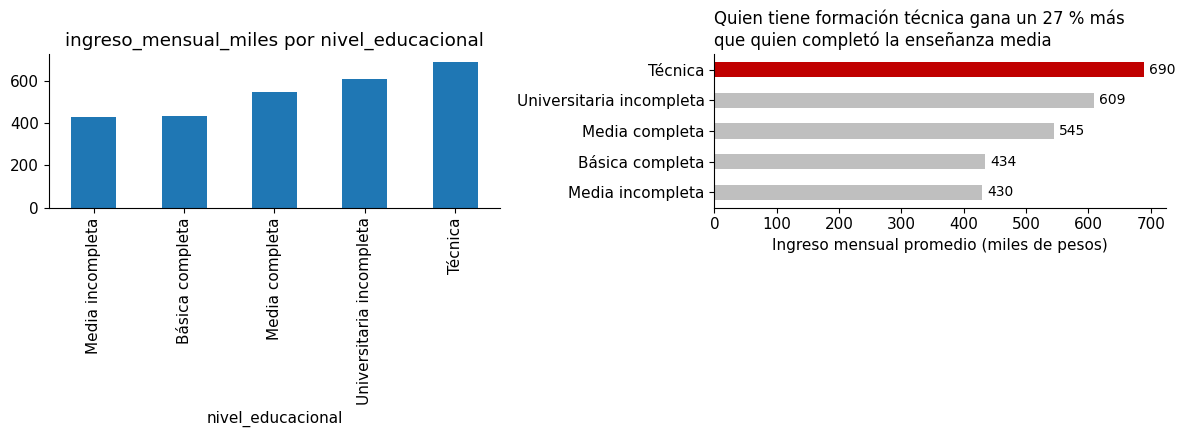

Verificación del titular: 26.6%


In [3]:
ingreso = p.groupby('nivel_educacional')['ingreso_mensual_miles'].mean().sort_values()

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# --- EXPLORATORIO: rápido, sin adornos, para mirarlo tú
ingreso.plot.bar(ax=ax[0])
ax[0].set_title('ingreso_mensual_miles por nivel_educacional')

# --- EXPLICATIVO: una idea, destacada
colores = ['#BFBFBF'] * len(ingreso)
colores[-1] = '#C00000'
ingreso.plot.barh(ax=ax[1], color=colores)
ax[1].set_title('Quien tiene formación técnica gana un 27 % más\nque quien completó la enseñanza media', loc='left', fontsize=12)
ax[1].set_xlabel('Ingreso mensual promedio (miles de pesos)')
ax[1].set_ylabel('')
for i, v in enumerate(ingreso):
    ax[1].text(v + 8, i, f'{v:,.0f}'.replace(',', '.'), va='center', fontsize=10)
plt.tight_layout(); plt.show()

print(f"Verificación del titular: {ingreso['Técnica']/ingreso['Media completa']-1:.1%}")

Cuatro cambios convierten uno en otro, y ninguno es decorativo:

1. **Barras horizontales**: las etiquetas largas se leen sin girar la cabeza.
2. **Gris salvo lo que importa**: el color dirige la mirada. Si todo es de colores, nada destaca.
3. **El valor sobre la barra**: quien quiera el número exacto no tiene que estimarlo contra el eje.
4. **Título que enuncia el hallazgo**, con la cifra verificada en la celda.

> **Verifica siempre el número que pones en el título.** Es el error más embarazoso posible: un titular que el propio gráfico desmiente.

### 1.2 Elegir el gráfico según la pregunta

| Si la pregunta es… | El gráfico es… | Evita |
|---|---|---|
| ¿Cuánto hay de cada categoría? | Barras (horizontales si son muchas o largas) | Torta con más de 4 porciones |
| ¿Cómo cambió en el tiempo? | Línea | Barras, que sugieren categorías independientes |
| ¿Cómo se distribuye una variable? | Histograma o caja | Solo el promedio |
| ¿Se relacionan dos variables? | Dispersión | Dos líneas con ejes distintos |
| ¿Cómo se compone un total? | Barras apiladas | Torta anidada, ilegible |

### ✏️ Actividad 1.1

Toma **dos hallazgos** de tu conjunto (semanas 3 y 4) y construye su versión explicativa. Para cada uno: elige el tipo según la pregunta, deja en gris lo secundario, rotula los valores y escribe un título que enuncie el hallazgo con su cifra.

Estos dos gráficos van al informe final.

In [4]:
mio = pd.read_csv(RUTA + 'mi_conjunto_minado.csv', sep=';')
print(mio.shape)
# Tu código aquí


(202403, 18)


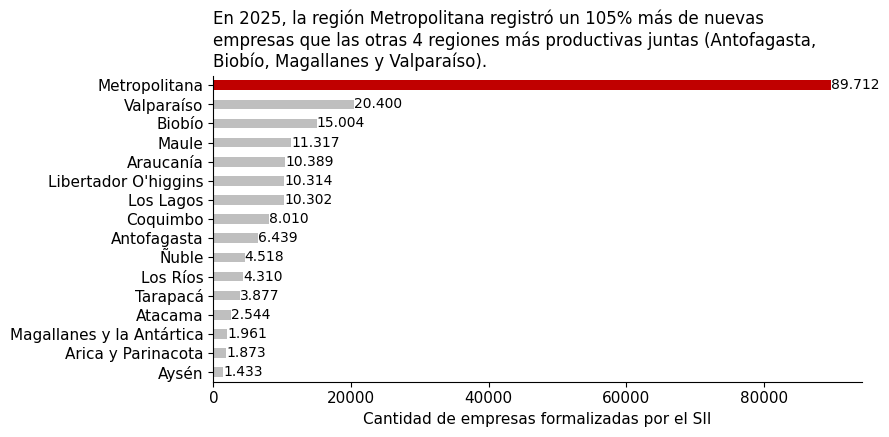

Metropolitana                               : 89.712
Suma de las otras 4 regiones más productivas: 43.804
Metropolitana por sobre las 4 regiones      : 104.8%


In [5]:
# Ponemos nombre a las regiones
regionTexto = {1: "Tarapacá", 2: "Antofagasta", 3: "Atacama", 4: "Coquimbo",
                5: "Valparaíso", 6: "Libertador O'higgins", 7: "Maule", 8: "Biobío",
                9: "Araucanía", 10: "Los Lagos", 11: "Aysén", 12: "Magallanes y la Antártica",
                13: "Metropolitana", 14: "Los Ríos", 15: "Arica y Parinacota", 16: "Ñuble"}
mio["region_texto"] = mio["Region Tributaria"].map(regionTexto)

# Gráfico de barras horizontal
empresas = mio.groupby('region_texto')['ID'].count().sort_values()
fig, ax = plt.subplots(figsize=(9, 4.5))
colores = ['#BFBFBF'] * len(empresas)
colores[-1] = '#C00000'
empresas.plot.barh(ax=ax, color=colores)
titulo = ("En 2025, la región Metropolitana registró un 105% más de nuevas empresas "
          "que las otras 4 regiones más productivas juntas (Antofagasta, Biobío, Magallanes y Valparaíso).")
ax.set_title(textwrap.fill(titulo, width=70), loc="left", fontsize=12)
ax.set_xlabel('Cantidad de empresas formalizadas por el SII')
ax.set_ylabel('')

for i, v in enumerate(empresas):
    ax.text(v + 8, i, f'{v:,.0f}'.replace(',', '.'), va='center', fontsize=10)
plt.tight_layout(); plt.show()

cuatro_regiones = (
    empresas["Antofagasta"]
    + empresas["Biobío"]
    + empresas["Magallanes y la Antártica"]
    + empresas["Valparaíso"]
)

# Comparamos el crecimiento en %
print(f"Metropolitana                               : {empresas['Metropolitana']:,}".replace(",", "."))
print(f"Suma de las otras 4 regiones más productivas: {cuatro_regiones:,}".replace(",", "."))
print(f"Metropolitana por sobre las 4 regiones      : {empresas['Metropolitana'] / cuatro_regiones - 1:.1%}")

---
## Parte 2 · Representación honesta

Los dos gráficos de `S5_Graficos_Prensa_CDD.pdf` no contienen ningún dato falso. Vamos a reproducir sus distorsiones para entender exactamente qué hacen.

### 2.1 El eje truncado

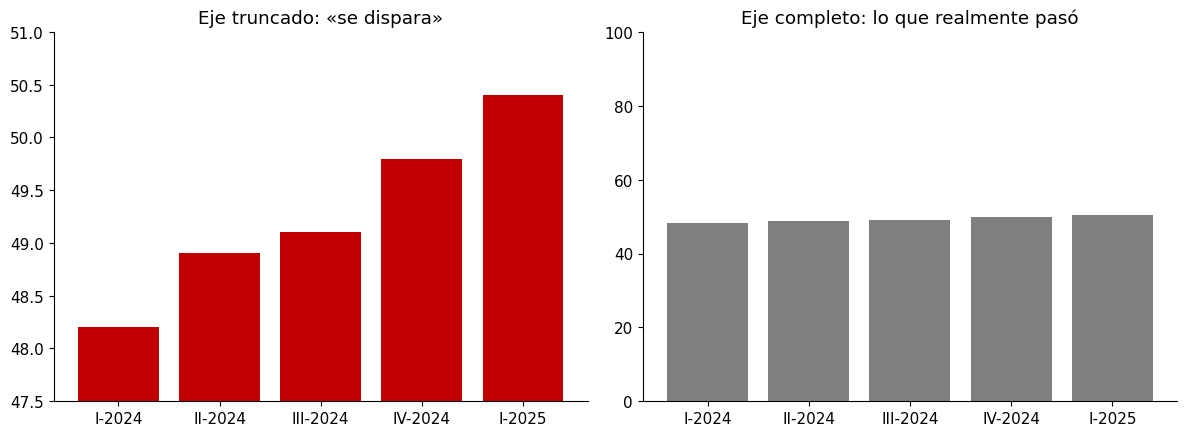

Variación real: 2.2 puntos = 4.6 %


In [6]:
trimestres = ['I-2024', 'II-2024', 'III-2024', 'IV-2024', 'I-2025']
satisfaccion = [48.2, 48.9, 49.1, 49.8, 50.4]

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].bar(trimestres, satisfaccion, color='#C00000')
ax[0].set_ylim(47.5, 51)
ax[0].set_title('Eje truncado: «se dispara»')

ax[1].bar(trimestres, satisfaccion, color='#7F7F7F')
ax[1].set_ylim(0, 100)
ax[1].set_title('Eje completo: lo que realmente pasó')
plt.tight_layout(); plt.show()

print(f'Variación real: {satisfaccion[-1] - satisfaccion[0]:.1f} puntos = '
      f'{(satisfaccion[-1]/satisfaccion[0] - 1)*100:.1f} %')

El mismo dato. A la izquierda parece una explosión; a la derecha, una línea casi plana. El aumento real es de **2,2 puntos, un 4,6 %**.

> **¿Truncar el eje es siempre deshonesto?** No. En una serie que oscila entre 48 y 51 nunca, mostrar desde cero puede ocultar variación relevante. La regla practicable es: **en gráficos de barras, el eje parte en cero** —porque la barra comunica magnitud por su largo—; **en gráficos de línea puedes truncar**, siempre que lo señales de forma visible.

### 2.2 Magnitudes brutas entre unidades de distinto tamaño

Esta es la misma trampa de la semana 3, ahora en formato gráfico.

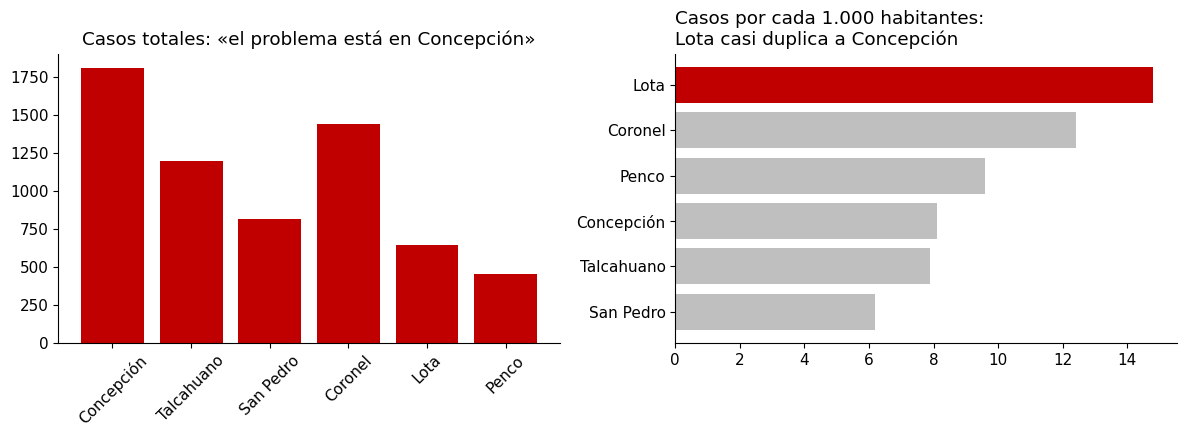

Lota             644 casos ·  14.8 por mil habitantes
Coronel         1441 casos ·  12.4 por mil habitantes
Penco            452 casos ·   9.6 por mil habitantes
Concepción      1810 casos ·   8.1 por mil habitantes
Talcahuano      1198 casos ·   7.9 por mil habitantes
San Pedro        817 casos ·   6.2 por mil habitantes


In [7]:
comunas = ['Concepción', 'Talcahuano', 'San Pedro', 'Coronel', 'Lota', 'Penco']
poblacion = [223574, 151749, 131808, 116262, 43535, 47105]
tasa = [8.1, 7.9, 6.2, 12.4, 14.8, 9.6]          # por cada 1.000 habitantes
casos = [int(pob * t / 1000) for pob, t in zip(poblacion, tasa)]

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].bar(comunas, casos, color='#C00000')
ax[0].set_title('Casos totales: «el problema está en Concepción»')
ax[0].tick_params(axis='x', rotation=45)

orden = np.argsort(tasa)
col = ['#BFBFBF'] * 6
col[list(orden).index(4)] = '#C00000'
ax[1].barh([comunas[i] for i in orden], [tasa[i] for i in orden],
           color=[col[i] for i in range(6)])
ax[1].set_title('Casos por cada 1.000 habitantes:\nLota casi duplica a Concepción', loc='left')
plt.tight_layout(); plt.show()

for c, t, k in sorted(zip(comunas, tasa, casos), key=lambda x: -x[1]):
    print(f'{c:14s} {k:5d} casos · {t:5.1f} por mil habitantes')

A la izquierda, Concepción encabeza. A la derecha, **Concepción es de las más bajas** y Lota casi la duplica. Los datos son los mismos.

> **Regla:** si las unidades que comparas tienen tamaños distintos, normaliza antes de graficar. Casos por mil habitantes, ventas por metro cuadrado, accidentes por kilómetro recorrido.

### ✏️ Actividad 2.1

Revisa tus dos gráficos de la actividad 1.1 y responde:

- ¿Algún eje está truncado? Si lo está, ¿se justifica y está señalado?
- ¿Comparas unidades de distinto tamaño sin normalizar?
- ¿El título afirma algo que el gráfico no muestra?
- ¿Omites algún período o categoría que cambiaría la lectura?

_Tu autorrevisión:_



---
## Parte 3 · Anonimización

Trabajamos sobre `S5_Dataset_Personales_Sintetico_CDD.csv`: 420 participantes de un programa municipal de capacitación.

⚠️ **Los datos son sintéticos**: nombres, RUT y direcciones fueron generados artificialmente para este curso. Los RUT usan un rango no asignado a personas naturales. **No corresponden a nadie real.**

In [8]:
p = pd.read_csv(RUTA + 'S5_Dataset_Personales_Sintetico_CDD.csv', sep=';')
print('Forma:', p.shape)
p.head(3)

Forma: (420, 15)


,participante_id,nombre_completo,rut,email,fecha_nacimiento,sexo,comuna,direccion,ocupacion,nivel_educacional,situacion_laboral,ingreso_mensual_miles,programa,asistencia_pct,aprobado
0,P0001,Florencia Pérez Araya,93.939.245-8,florencia.pérez73@correo.cl,1968-07-09,M,Coronel,Prat 786,Panadero,Universitaria incompleta,Inactivo,618,Alfabetización digital,80,Sí
1,P0002,Florencia Silva Valenzuela,91.854.251-6,florencia.silva25@correo.cl,1978-01-21,M,Lota,Maipú 3523,Panadero,Técnica,Ocupado,914,Emprendimiento,59,No
2,P0003,Paula Fuentes Torres,94.822.480-K,paula.fuentes59@correo.cl,1998-03-13,F,Concepción,Barros Arana 1620,Profesor de educación básica,Universitaria incompleta,Desocupado,482,Apresto laboral,82,Sí


### 3.1 Los tres tipos de identificador

| Tipo | Qué es | En este conjunto |
|---|---|---|
| **Identificador directo** | Identifica por sí solo | nombre_completo, rut, email, direccion |
| **Cuasi-identificador** | No identifica solo, pero sí **en combinación** | comuna, sexo, fecha_nacimiento, ocupacion |
| **Atributo sensible** | Lo que no queremos revelar de nadie | ingreso_mensual_miles, situacion_laboral |

El error clásico es creer que basta con borrar la primera fila de la tabla. Vamos a comprobar que no.

### 3.2 Paso 1 · Quitar los identificadores directos

In [9]:
DIRECTOS = ['nombre_completo', 'rut', 'email', 'direccion']
anon = p.drop(columns=DIRECTOS).copy()
print('Columnas restantes:', list(anon.columns))
anon.head(3)

Columnas restantes: ['participante_id', 'fecha_nacimiento', 'sexo', 'comuna', 'ocupacion', 'nivel_educacional', 'situacion_laboral', 'ingreso_mensual_miles', 'programa', 'asistencia_pct', 'aprobado']


,participante_id,fecha_nacimiento,sexo,comuna,ocupacion,nivel_educacional,situacion_laboral,ingreso_mensual_miles,programa,asistencia_pct,aprobado
0,P0001,1968-07-09,M,Coronel,Panadero,Universitaria incompleta,Inactivo,618,Alfabetización digital,80,Sí
1,P0002,1978-01-21,M,Lota,Panadero,Técnica,Ocupado,914,Emprendimiento,59,No
2,P0003,1998-03-13,F,Concepción,Profesor de educación básica,Universitaria incompleta,Desocupado,482,Apresto laboral,82,Sí


Sin nombre, sin RUT, sin correo y sin dirección. **¿Está anonimizado?**

### 3.3 Paso 2 · Medir el k-anonimato

El **k-anonimato** mide cuántas personas comparten exactamente la misma combinación de cuasi-identificadores. Si k = 1, esa persona es **única en el conjunto**: quien conozca esos cuatro datos suyos la encuentra sin más.

In [10]:
QI = ['comuna', 'sexo', 'fecha_nacimiento', 'ocupacion']
grupos = anon.groupby(QI).size()

print(f'Combinaciones distintas : {len(grupos)}')
print(f'Personas con k = 1      : {(grupos == 1).sum()}  '
      f'({(grupos == 1).sum()/len(anon)*100:.1f} % del conjunto)')
print(f'k mínimo                : {grupos.min()}')

Combinaciones distintas : 420
Personas con k = 1      : 420  (100.0 % del conjunto)
k mínimo                : 1


**420 de 420.** Todas las personas son únicas. El conjunto no está anonimizado en absoluto: cualquiera que sepa la comuna, el sexo, la fecha de nacimiento y el oficio de un conocido puede encontrar su ingreso y su situación laboral.

> Esto no es una hipótesis de laboratorio. En 2006 Netflix publicó un conjunto «anonimizado» de calificaciones de películas; investigadores reidentificaron usuarios cruzándolo con IMDb. En 2014, los registros de taxis de Nueva York permitieron rastrear viajes individuales.

### 3.4 Paso 3 · Generalizar

In [11]:
anon['anio_nacimiento'] = pd.to_datetime(anon['fecha_nacimiento']).dt.year
anon['tramo_edad'] = ((2026 - anon['anio_nacimiento']) // 10 * 10).astype(str) + '-' + \
                     (((2026 - anon['anio_nacimiento']) // 10 * 10) + 9).astype(str)
anon = anon.drop(columns=['fecha_nacimiento', 'anio_nacimiento', 'ocupacion'])

g2 = anon.groupby(['comuna', 'sexo', 'tramo_edad']).size()
print(f'Combinaciones : {len(g2)}')
print(f'Personas k = 1: {(g2 == 1).sum()}')
print(f'k mínimo      : {g2.min()}')

Combinaciones : 97
Personas k = 1: 5
k mínimo      : 1


De 420 únicos bajamos a 5. Mejor, pero **cinco personas siguen siendo identificables**.

### 3.5 Paso 4 · Generalizar un nivel más

In [12]:
# Las diez comunas pertenecen a la Provincia de Concepción
anon['provincia'] = 'Concepción'
g3 = anon.groupby(['provincia', 'sexo', 'tramo_edad']).size()
print(f'Combinaciones : {len(g3)}')
print(f'Personas k = 1: {(g3 == 1).sum()}')
print(f'k mínimo      : {g3.min()}')
print('\nTamaño de cada grupo:')
print(g3.sort_values().to_string())

Combinaciones : 10
Personas k = 1: 0
k mínimo      : 23

Tamaño de cada grupo:
provincia   sexo  tramo_edad
Concepción  M     20-29         23
            F     20-29         35
            M     50-59         37
            F     40-49         38
                  60-69         40
                  30-39         43
            M     60-69         43
                  30-39         52
                  40-49         52
            F     50-59         57


Ahora **ninguna persona es única** y el grupo más pequeño tiene 23 integrantes. El conjunto cumple k-anonimato con k = 23.

> **El precio de la privacidad es resolución.** Perdimos la comuna y el oficio: ya no podemos comparar Lota con Concepción. Ese es el intercambio, y es una decisión que se declara en el informe, no un detalle técnico.

### ✏️ Actividad 3.1 — Seudonimización

A veces necesitas seguir a la misma persona entre dos archivos sin saber quién es. Para eso sirve el **seudónimo**: un código estable que reemplaza al identificador.

Escribe el código que genere un seudónimo para cada participante a partir de su RUT, usando una función de resumen (`hashlib.sha256`). Después responde: **¿por qué un seudónimo NO es lo mismo que una anonimización?**

In [16]:
import hashlib

# Tu código aquí. Referencia:
def seudonimo(valor, sal='CDD-2026'):
  return hashlib.sha256((sal + str(valor)).encode()).hexdigest()[:12]

p['rut_seudonimo'] = p['rut'].apply(seudonimo)

p[['participante_id', 'rut', 'rut_seudonimo']].head(20)

,participante_id,rut,rut_seudonimo
0,P0001,93.939.245-8,e87d78b75a09
1,P0002,91.854.251-6,8bec038871af
2,P0003,94.822.480-K,5e7367c99892
3,P0004,90.640.340-6,0e0383cb030e
4,P0005,97.378.918-5,037c173c3e01
5,P0006,97.278.387-6,6f020227844e
6,P0007,95.961.674-1,e972e11a33f2
7,P0008,93.745.488-K,6b178114950b
8,P0009,91.593.917-2,aac8ff704230
9,P0010,99.887.992-6,481737217720


_Tu respuesta:_

Porque un seudónimo cifra el identificador (el rut del participante), mientras que la anonimización es el proceso de descartar y eliminar culquier variable que identifique o cuasi-identifique al individuo en cuestión.

---
## Parte 4 · Detección de sesgo

Un conjunto de datos puede estar limpio, ser representativo de lo que registra, y **aun así** llevar a decisiones injustas. El sesgo no está en los cálculos: está en qué se registró y a quién.

### 4.1 ¿Quién está en el conjunto?

In [17]:
print('Composición del programa:\n')
for col in ['sexo', 'nivel_educacional', 'situacion_laboral']:
    print(col.upper())
    print(p[col].value_counts(normalize=True).round(3).to_string())
    print()

Composición del programa:

SEXO
sexo
F    0.507
M    0.493

NIVEL_EDUCACIONAL
nivel_educacional
Media completa              0.414
Técnica                     0.207
Media incompleta            0.160
Universitaria incompleta    0.110
Básica completa             0.110

SITUACION_LABORAL
situacion_laboral
Ocupado       0.612
Desocupado    0.276
Inactivo      0.112



### 4.2 ¿A quién no describe?

Esta es la pregunta que casi nadie hace, y la que más consecuencias tiene.

Este conjunto contiene a quienes **se inscribieron y participaron** en el programa. No contiene a quienes no se enteraron, a quienes no pudieron asistir por horario o transporte, ni a quienes abandonaron antes del registro.

> Si con estos datos concluyes «el programa funciona, el 57 % aprueba», estás describiendo a los participantes, no a la población objetivo. Es exactamente el error de las encuestas de satisfacción respondidas solo por quienes quisieron responder.

In [18]:
# Comprobación: ¿el resultado depende de algún grupo?
tabla = p.groupby('nivel_educacional').agg(
    n=('aprobado', 'size'),
    tasa_aprobacion=('aprobado', lambda s: (s == 'Sí').mean()),
    asistencia_media=('asistencia_pct', 'mean'),
).round(3).sort_values('tasa_aprobacion')
tabla

,n,tasa_aprobacion,asistencia_media
nivel_educacional,,,
Básica completa,46,0.500,77.348
Técnica,87,0.540,76.161
Universitaria incompleta,46,0.587,74.717
Media completa,174,0.609,77.103
Media incompleta,67,0.642,78.328


### ✏️ Actividad 4.1 — El sesgo de tu conjunto

Responde sobre **tu propio conjunto de datos**, en la celda siguiente. Estas tres respuestas van íntegras a la sección de limitaciones de tu informe final:

1. **¿Quién queda fuera?** ¿Qué personas, casos o situaciones no están registrados y por qué?
2. **¿El modo de recolección favorece a algún grupo?** ¿Quién tuvo más probabilidad de quedar registrado?
3. **¿Qué conclusión equivocada sacaría alguien que ignore esa ausencia?** Escríbela textualmente: es la advertencia que debes incluir en el informe.

_Tu respuesta:_

**1. Quién queda fuera:** …

**2. Sesgo de recolección:** …

**3. Conclusión equivocada que hay que prevenir:** …

---
## Parte 5 · Cerrar la ficha ético-legal

Abre `S1_Ficha_Riesgo_Etico_CDD.docx`, la que completaste en la semana 1, y ciérrala con lo que ahora sabes:

- **Punto 4 (riesgos y resguardos):** qué resguardos aplicaste efectivamente durante la preparación y el análisis, no los que pensabas aplicar.
- **Punto 5 (sesgo):** las tres respuestas de la actividad 4.1.
- **Punto 6 (declaración de uso):** fírmala.

Esa ficha cerrada **es la Sección C de la Entrega Final**, junto con tu plan de actualización.

---
## Cierre y versionado

In [ ]:
# Guarda las figuras del informe en archivos, para insertarlas en el documento
# fig.savefig('figura_1.png', dpi=200, bbox_inches='tight')
print('Recuerda exportar tus dos gráficos explicativos a .png con dpi=200')

In [ ]:
# En una terminal:
# git add S5_Notebook_Laboratorio_CDD.ipynb figura_*.png
# git commit -m 'Semana 5: visualizaciones explicativas, anonimizacion y sesgo'
# git push


**Enlace a mi repositorio:** _…_

---

## Antes de cerrar el laboratorio

- [ ] Dos gráficos explicativos, con título que enuncia el hallazgo y cifra verificada
- [ ] Autorrevisión de honestidad: ejes, normalización, títulos, omisiones
- [ ] Recorrido de anonimización completo, con el k-anonimato medido en cada paso
- [ ] Seudonimización implementada y explicada
- [ ] Las tres respuestas sobre el sesgo de mi conjunto
- [ ] Ficha ético-legal cerrada y firmada
- [ ] Figuras exportadas a .png para el informe

_Ciencia de Datos · Advance UCSC · Semana 5_